# Customer Segmentation Project
**Objective:** Customers ko unke behavior (purchase patterns) aur demographics ke basis par segments mein divide karna, taaki targeted marketing insights mil sakein.

**Tools:** Python, pandas, scikit-learn (KMeans, PCA), matplotlib, seaborn

**Steps:**
1. Data load / generate
2. EDA (Exploratory Data Analysis)
3. Feature scaling
4. Optimal clusters (Elbow + Silhouette)
5. KMeans clustering
6. Segment visualization (PCA, scatter, radar-style profile)
7. Segment profiling and business insights

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Dataset
Yahan ek realistic retail dataset generate kiya gaya hai (1000 customers) jisme demographics aur purchase behavior dono hain. Agar aapke paas apna CSV hai (jaise Kaggle ka *Mall Customers*), to neeche `df = pd.read_csv('your_file.csv')` use karke replace kar sakte hain.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

def make_group(n, age, income, spend, freq, aov, recency, online):
    return pd.DataFrame({
        'Age': np.clip(rng.normal(age[0], age[1], n), 18, 70).round(),
        'Annual_Income_k': np.clip(rng.normal(income[0], income[1], n), 10, 160).round(1),
        'Spending_Score': np.clip(rng.normal(spend[0], spend[1], n), 1, 100).round(),
        'Purchase_Frequency': np.clip(rng.normal(freq[0], freq[1], n), 1, 60).round(),
        'Avg_Order_Value': np.clip(rng.normal(aov[0], aov[1], n), 5, 400).round(2),
        'Days_Since_Last_Purchase': np.clip(rng.normal(recency[0], recency[1], n), 1, 365).round(),
        'Online_Purchase_Ratio': np.clip(rng.normal(online[0], online[1], n), 0, 1).round(2),
    })

df = pd.concat([
    make_group(250, (24, 4), (35, 8),  (78, 10), (30, 6), (45, 12),  (12, 8),  (0.85, 0.08)),  # young trendy spenders
    make_group(220, (42, 6), (95, 15), (82, 9),  (24, 5), (190, 35), (18, 10), (0.55, 0.12)),  # affluent premium buyers
    make_group(260, (46, 9), (55, 12), (45, 10), (10, 3), (70, 15),  (60, 20), (0.40, 0.15)),  # average occasional
    make_group(150, (58, 6), (40, 10), (20, 8),  (4, 2),  (35, 10),  (140, 40),(0.20, 0.10)),  # older, low activity
    make_group(120, (35, 8), (100, 14),(20, 8),  (5, 2),  (110, 25), (95, 30), (0.50, 0.15)),  # high income, low spend
], ignore_index=True).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

df.insert(0, 'CustomerID', range(1001, 1001 + len(df)))
df['Gender'] = rng.choice(['Male', 'Female'], size=len(df), p=[0.46, 0.54])
df.to_csv('customer_data.csv', index=False)
df.head()

,CustomerID,Age,Annual_Income_k,Spending_Score,Purchase_Frequency,Avg_Order_Value,Days_Since_Last_Purchase,Online_Purchase_Ratio,Gender
0,1001,53.0,84.0,52.0,12.0,74.69,48.0,0.41,Female
1,1002,57.0,20.0,28.0,2.0,30.37,193.0,0.05,Female
2,1003,59.0,48.7,28.0,6.0,36.52,147.0,0.19,Male
3,1004,42.0,36.0,48.0,11.0,54.16,53.0,0.40,Male
4,1005,45.0,130.1,88.0,27.0,186.20,14.0,0.73,Male


## 2. Exploratory Data Analysis

In [3]:
print(df.shape)
print(df.isnull().sum().sum(), 'missing values')
df.describe().T

(1000, 9)
0 missing values


,count,mean,std,min,25%,50%,75%,max
CustomerID,1000.0,1500.50000,288.819436,1001.0,1250.750,1500.500,1750.2500,2000.00
Age,1000.0,39.89600,13.034227,18.0,28.750,40.000,49.0000,70.00
Annual_Income_k,1000.0,62.54410,28.710557,14.5,38.700,53.850,88.0000,137.90
Spending_Score,1000.0,54.17400,26.793649,1.0,29.000,54.500,79.0000,100.00
Purchase_Frequency,1000.0,16.77300,11.294824,1.0,6.000,13.500,27.0000,49.00
Avg_Order_Value,1000.0,89.63825,61.486289,5.0,44.275,66.255,124.5975,282.22
Days_Since_Last_Purchase,1000.0,55.52800,51.891907,1.0,15.000,37.500,82.0000,268.00
Online_Purchase_Ratio,1000.0,0.52172,0.244162,0.0,0.340,0.500,0.7200,1.00


/tmp/ipykernel_149/674698425.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender', data=df, ax=axes[1,3], palette='Blues')


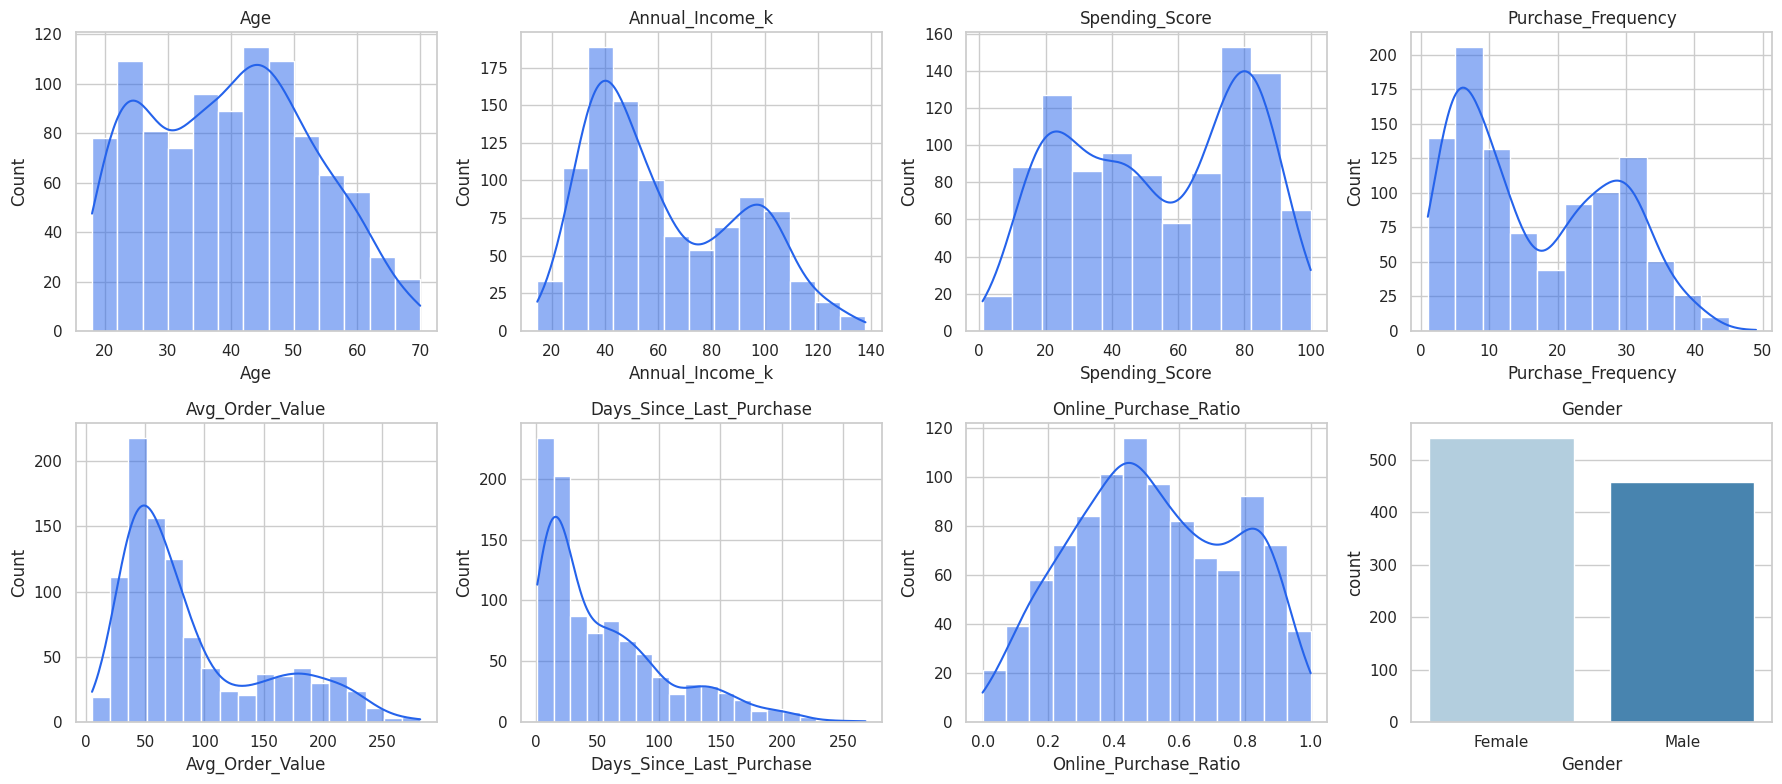

In [4]:
num_cols = ['Age','Annual_Income_k','Spending_Score','Purchase_Frequency','Avg_Order_Value','Days_Since_Last_Purchase','Online_Purchase_Ratio']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='#2563eb')
    ax.set_title(col)
sns.countplot(x='Gender', data=df, ax=axes[1,3], palette='Blues')
axes[1,3].set_title('Gender')
plt.tight_layout()
plt.savefig('01_distributions.png', dpi=150)
plt.show()

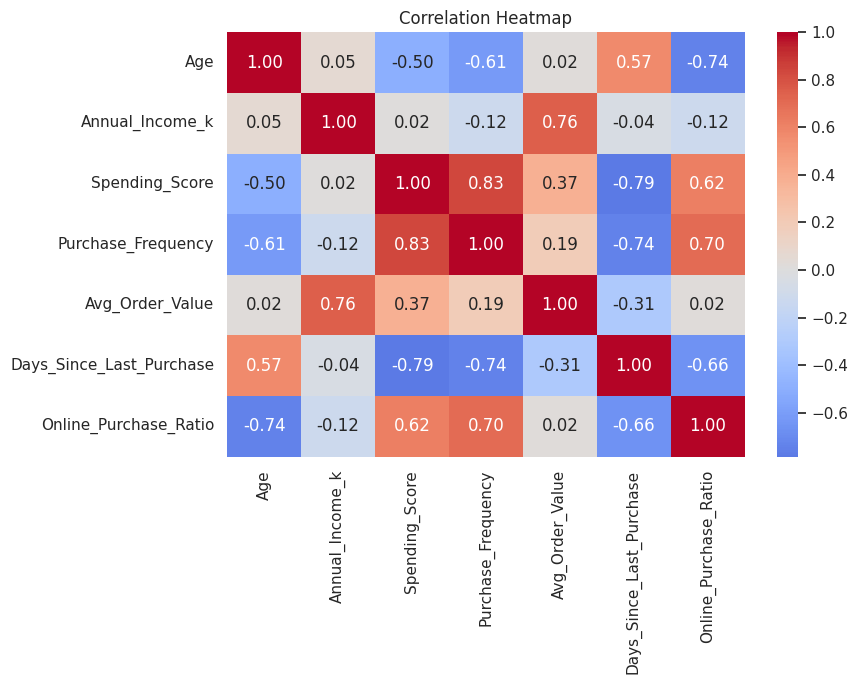

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('02_correlation.png', dpi=150)
plt.show()

## 3. Feature Selection and Scaling
Clustering distance-based hoti hai, isliye features ko standardize karna zaroori hai.

In [6]:
features = ['Age','Annual_Income_k','Spending_Score','Purchase_Frequency','Avg_Order_Value','Days_Since_Last_Purchase','Online_Purchase_Ratio']
X = df[features]
X_scaled = StandardScaler().fit_transform(X)

## 4. Optimal Number of Clusters
Elbow method (inertia) aur Silhouette score dono se best K choose karenge.

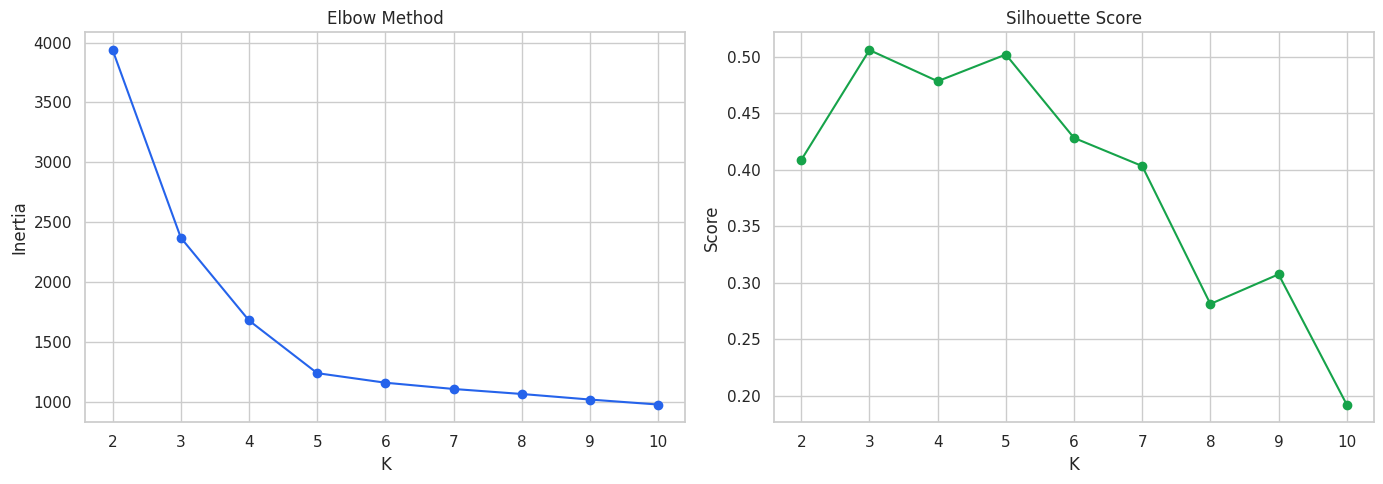

Best K by silhouette: 3 | score = 0.506


In [7]:
inertia, sil = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(K_range, inertia, 'o-', color='#2563eb'); ax[0].set_title('Elbow Method'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia')
ax[1].plot(K_range, sil, 'o-', color='#16a34a'); ax[1].set_title('Silhouette Score'); ax[1].set_xlabel('K'); ax[1].set_ylabel('Score')
plt.tight_layout()
plt.savefig('03_elbow_silhouette.png', dpi=150)
plt.show()

best_k = list(K_range)[int(np.argmax(sil))]
print('Best K by silhouette:', best_k, '| score =', round(max(sil), 3))

## 5. KMeans Clustering
**K=5 kyun?** Silhouette score K=3 par thoda zyada hai (0.506), lekin K=5 par bhi lagbhag same hai (0.502). K=3 sirf broad groups deta hai, jabki K=5 par 5 distinct, actionable business segments milte hain (elbow curve mein bhi K=5 ke aas-paas bend dikhta hai). Isliye business interpretability ke liye K=5 choose kiya gaya.

In [8]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print('Silhouette score (K=5):', round(silhouette_score(X_scaled, df['Cluster']), 3))
df['Cluster'].value_counts().sort_index()

Silhouette score (K=5): 0.502


Cluster
0    251
1    146
2    220
3    262
4    121
Name: count, dtype: int64

## 6. Visualizing the Segments

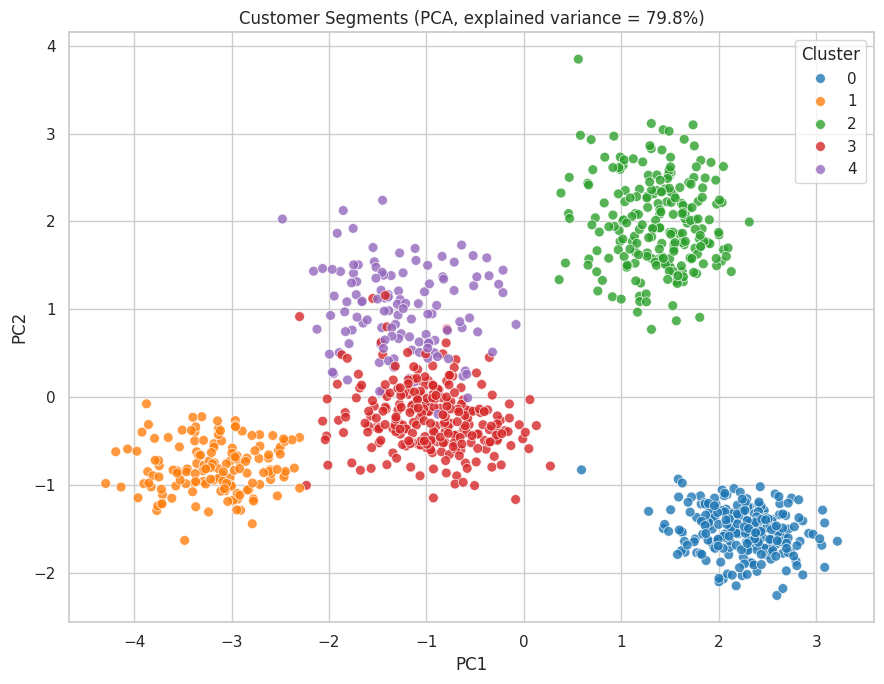

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
df['PC1'], df['PC2'] = pcs[:,0], pcs[:,1]

plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x='PC1', y='PC2', hue='Cluster', palette='tab10', s=50, alpha=0.8)
plt.title(f'Customer Segments (PCA, explained variance = {pca.explained_variance_ratio_.sum():.1%})')
plt.tight_layout()
plt.savefig('04_pca_clusters.png', dpi=150)
plt.show()

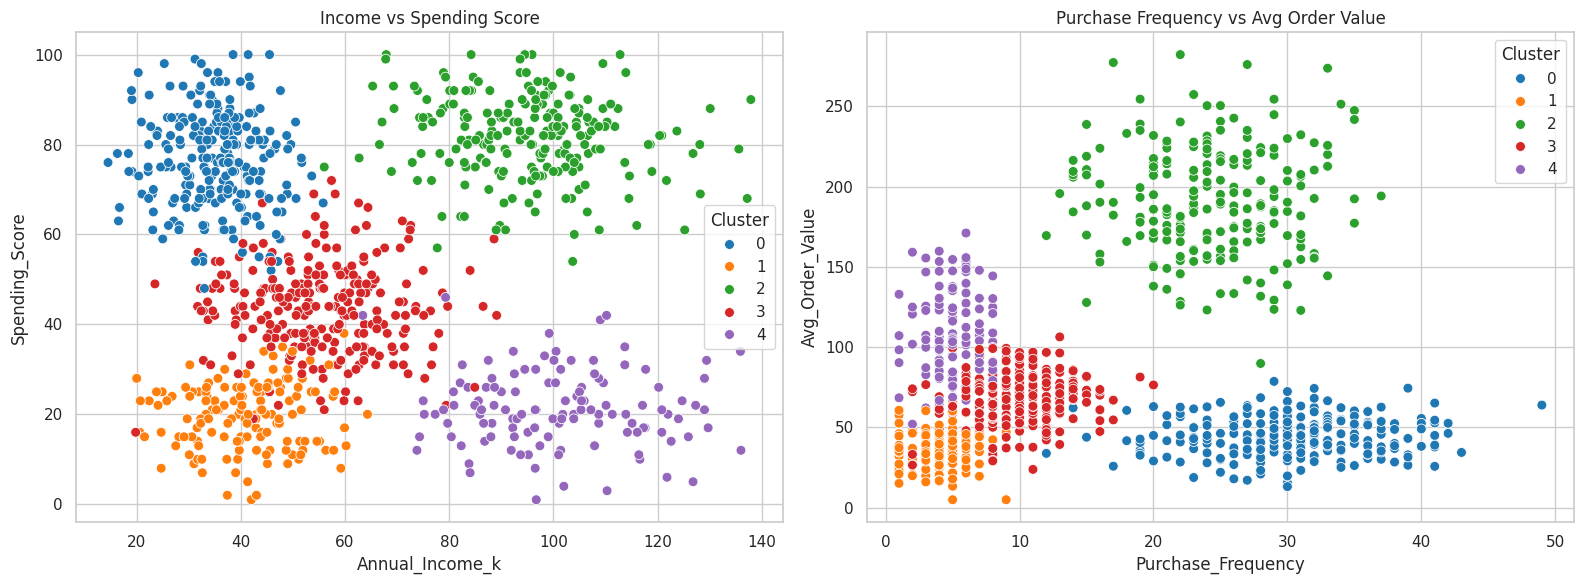

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df, x='Annual_Income_k', y='Spending_Score', hue='Cluster', palette='tab10', s=50, ax=ax[0])
ax[0].set_title('Income vs Spending Score')
sns.scatterplot(data=df, x='Purchase_Frequency', y='Avg_Order_Value', hue='Cluster', palette='tab10', s=50, ax=ax[1])
ax[1].set_title('Purchase Frequency vs Avg Order Value')
plt.tight_layout()
plt.savefig('05_cluster_scatter.png', dpi=150)
plt.show()

## 7. Segment Profiling

In [11]:
profile = df.groupby('Cluster')[features].mean().round(1)
profile['Customers'] = df['Cluster'].value_counts().sort_index()
profile['Share_%'] = (profile['Customers'] / len(df) * 100).round(1)
profile

,Age,Annual_Income_k,Spending_Score,Purchase_Frequency,Avg_Order_Value,Days_Since_Last_Purchase,Online_Purchase_Ratio,Customers,Share_%
Cluster,,,,,,,,,
0,23.9,35.2,76.8,30.1,44.8,12.7,0.8,251,25.1
1,58.0,41.2,19.6,4.2,36.2,147.4,0.2,146,14.6
2,40.8,95.4,81.8,24.4,190.8,18.7,0.6,220,22.0
3,46.5,55.2,43.8,10.1,68.9,57.6,0.4,262,26.2
4,35.3,101.0,21.3,5.0,108.4,95.8,0.5,121,12.1


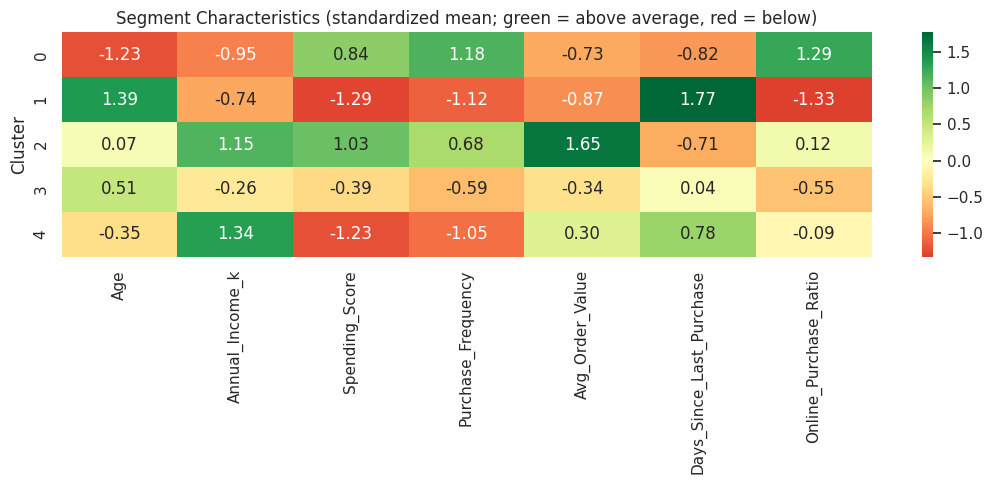

In [12]:
scaled_profile = pd.DataFrame(X_scaled, columns=features).groupby(df['Cluster']).mean()
plt.figure(figsize=(11, 5))
sns.heatmap(scaled_profile, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.title('Segment Characteristics (standardized mean; green = above average, red = below)')
plt.tight_layout()
plt.savefig('06_segment_heatmap.png', dpi=150)
plt.show()

/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)
/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)
/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)


/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)
/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)
/tmp/ipykernel_149/3580584032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)


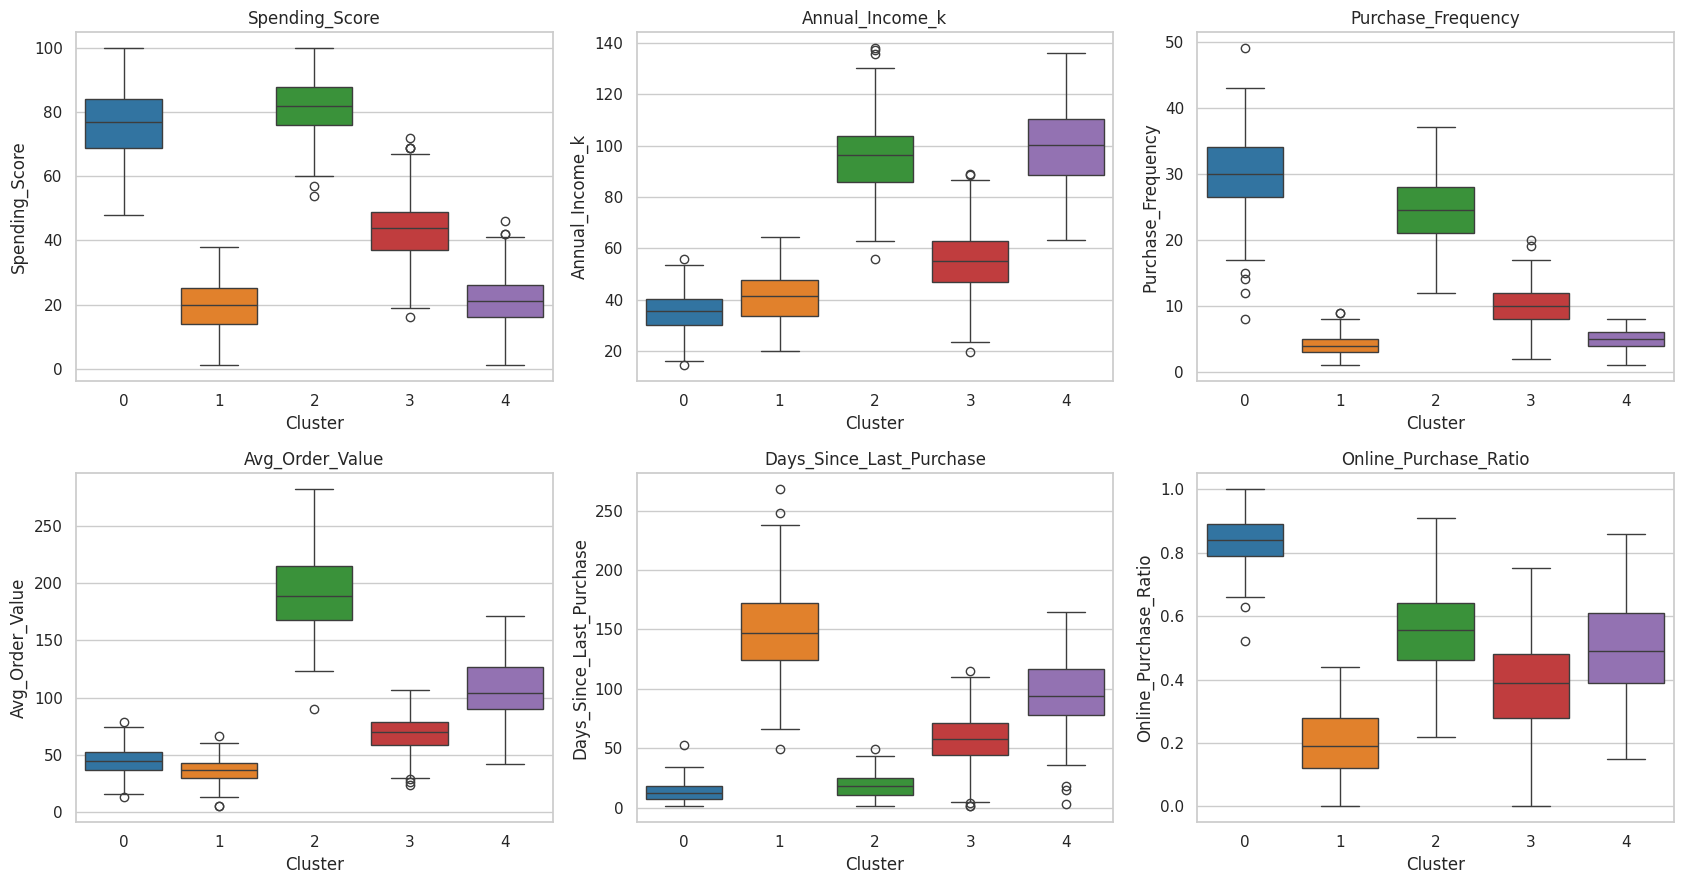

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), ['Spending_Score','Annual_Income_k','Purchase_Frequency','Avg_Order_Value','Days_Since_Last_Purchase','Online_Purchase_Ratio']):
    sns.boxplot(data=df, x='Cluster', y=col, palette='tab10', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('07_cluster_boxplots.png', dpi=150)
plt.show()

### Segment Naming
Profile aur heatmap dekhkar har cluster ko ek business-friendly naam dena hai. Neeche automatic rule-based naming hai jo cluster means par based hai.

Cluster
0             Young Trendsetters
1              At-Risk / Dormant
2              Premium Loyalists
3      Average Occasional Buyers
4    High-Income, Low-Engagement
dtype: str


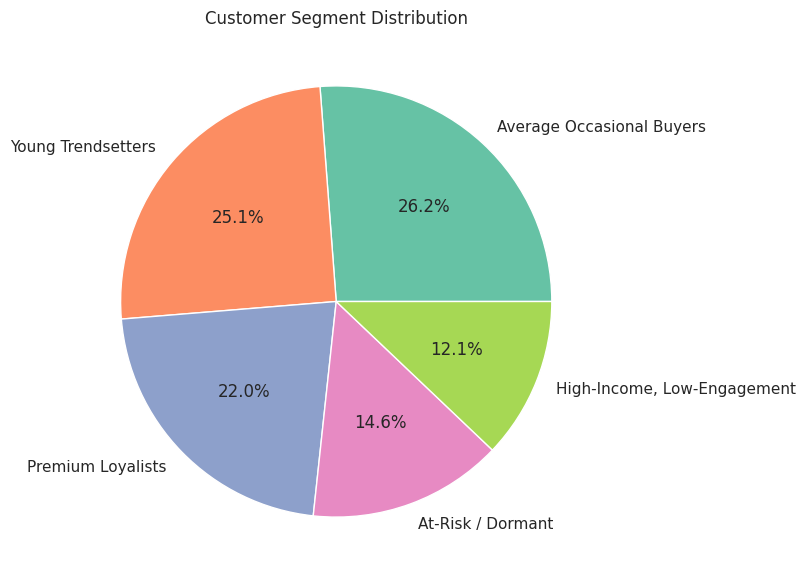

In [14]:
def name_segment(r):
    if r['Annual_Income_k'] > 80 and r['Spending_Score'] > 65:
        return 'Premium Loyalists'
    if r['Annual_Income_k'] > 80 and r['Spending_Score'] <= 65:
        return 'High-Income, Low-Engagement'
    if r['Age'] < 32 and r['Spending_Score'] > 65:
        return 'Young Trendsetters'
    if r['Days_Since_Last_Purchase'] > 100:
        return 'At-Risk / Dormant'
    return 'Average Occasional Buyers'

names = profile.apply(name_segment, axis=1)
print(names)
df['Segment'] = df['Cluster'].map(names)
df.to_csv('customers_segmented.csv', index=False)

df['Segment'].value_counts().plot.pie(autopct='%1.1f%%', figsize=(7,7), colors=sns.color_palette('Set2'))
plt.ylabel(''); plt.title('Customer Segment Distribution')
plt.savefig('08_segment_share.png', dpi=150)
plt.show()

## 8. Business Insights and Recommendations

| Segment | Behavior | Targeted Strategy |
|---|---|---|
| **Premium Loyalists** | High income, high spending, large orders | VIP/loyalty program, early access to new launches, premium bundles |
| **Young Trendsetters** | Young, very frequent, mostly online, small-to-medium orders | Social media campaigns, flash sales, referral rewards, app push notifications |
| **High-Income, Low-Engagement** | Can afford more but buy rarely | Personalized recommendations, re-engagement emails, premium trial offers |
| **Average Occasional Buyers** | Mid income, mid spend, moderate recency | Seasonal discounts, combo offers, cross-selling |
| **At-Risk / Dormant** | Older, low frequency, long time since last purchase | Win-back campaigns, discount coupons, offline/phone outreach |

## 9. Conclusion
- KMeans (K=5) ne customers ko clear, interpretable segments mein divide kiya (silhouette score ke saath validated).
- Purchase frequency, order value, recency aur income segments ke sabse bade differentiators hain.
- Har segment ke liye alag marketing strategy se retention aur revenue dono improve ho sakte hain.

**Future scope:** RFM analysis, DBSCAN / Hierarchical clustering comparison, real transactional data, Power BI dashboard.